# Libraries

In [ ]:
# Standard
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Science
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy.stats import shapiro
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

# Dataset

In [2]:
df_raw = pd.read_csv("processed_data/encoded.csv")

In [3]:
features_individual = ['sex', 'age']
features_school = ['failures', 'school', 'studytime']
features_family = ['Medu', 'Fedu', 'address', 'internet']
features_external = ['higher', 'Dalc', 'reason_reputation']

In [4]:
df = df_raw.copy()
independent_variables = features_individual + features_school
dependent_variable = ["G3"]
df = df[independent_variables + dependent_variable]

# Leaving out outliers

Given the results of Simple Linear Regression, only people who quit (G3 results = 0 or 1) will be considered outliers, since they did not perform the test or did not even study, altering the dataset.

In [5]:
print(df.shape)
df = df.loc[~(df_raw["G3"] <= 1)]
print(df.shape)

(649, 6)
(633, 6)


A logistic regression will be attempted in order to predict the probability of a student quitting

# Regression

In [6]:
X = df[independent_variables]
y = df["G3"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.228
Model:                            OLS   Adj. R-squared:                  0.222
Method:                 Least Squares   F-statistic:                     37.01
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           2.86e-33
Time:                        10:12:44   Log-Likelihood:                -1434.4
No. Observations:                 633   AIC:                             2881.
Df Residuals:                     627   BIC:                             2907.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.3636      1.365      6.858      0.0

* R-squared = *fraction of the variability of y explained by x*
    * 23% of variability explained
* Adjusted R-squared = *accounts for the number of independent variables. In simple linear regression, it is very similar to R-squared*
    * 22% of variability explained
* Prob (F-statistic) = *accounts for the statistical significativity of the model in its entirety. Null Hypothesis $H_0$ : model not significant*
    * close to 0, so statistically significant model even if with low variance explained
* P>|t| = *p-value of the coefficient, with the Null Hypothesis $H_0 : coef = 0$. When lower than 0.05, the coefficient is considered statistically significant*
    * Reject $H_0$ for all coefficients, so statistically significant for both coefficients
    * sex and age are the less significant

This time, to compare the relative importance of correlation coefficients, it is important to calculate standardized coefficients $\beta$.\
These coefficient indicate how much Y varies when X increases of 1 standard deviation

In [7]:
std_y = y.std()
std_x = df[independent_variables].std()

beta = model.params[independent_variables] * std_x / std_y

coefficients = pd.DataFrame({
    "B": model.params[independent_variables],
    "Beta": beta,
    "P-value": model.pvalues[independent_variables]
})

print(coefficients.sort_values(
    "Beta",
    key=abs,
    ascending=False
))

                  B      Beta       P-value
failures  -1.657853 -0.361302  1.093857e-20
school    -1.031465 -0.183371  4.006750e-07
studytime  0.512652  0.160784  1.230403e-05
sex       -0.437299 -0.080892  2.572748e-02
age        0.162229  0.074129  4.531821e-02


So: 
* failures is the most influent variable, 
* followed by school + studytime (almost $1/2$ of $\beta$ each), 
* followed by sex + age (almost $1/4$ of $\beta$ each)

The multicollinearity (how much independent variables are correlated) has also to be analyzed:
* VIF = 1 -> *no relevant issues*
* 1 < VIF < 5 -> *acceptable*
* VIF > 5 -> *attention*
* VIF > 10 -> *important multicollinearity*

In [8]:
vif = pd.DataFrame()

vif["Variable"] = X.columns
vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif)

    Variable         VIF
0      const  214.779428
1        sex    1.063158
2        age    1.109264
3   failures    1.135121
4     school    1.040357
5  studytime    1.080678


## Checking assumptions

Resuming all assumptions:
* linearity
    * graph of residuals -> not a good shape
* independence of errors (Durbin-Watson) -> OK
* homoscedasticity (equally dispersed)
    * graph -> many high values
    * Breusch-Pagan -> heteroscedastic
* normally distributed -> violated
    * Q-Q plot
    * Shapiro-Wilk

### Residuals

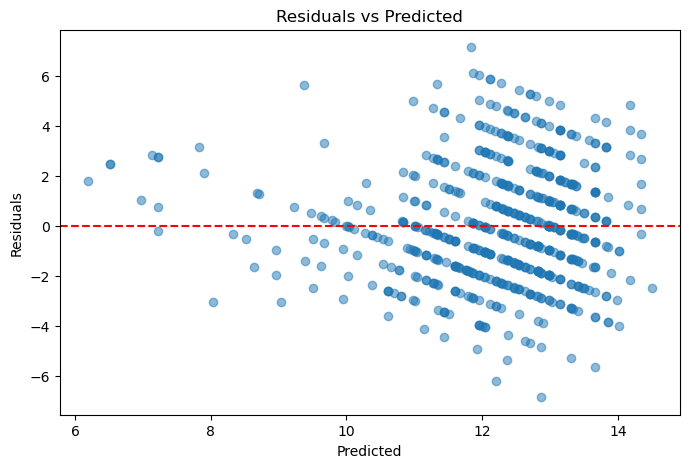

In [10]:
residuals = model.resid
predicted = model.fittedvalues

plt.figure(figsize=(8,5))

plt.scatter(predicted, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.show()

I can check residuals of every single variable

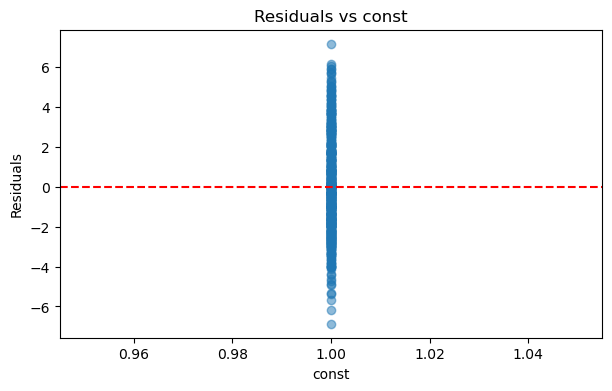

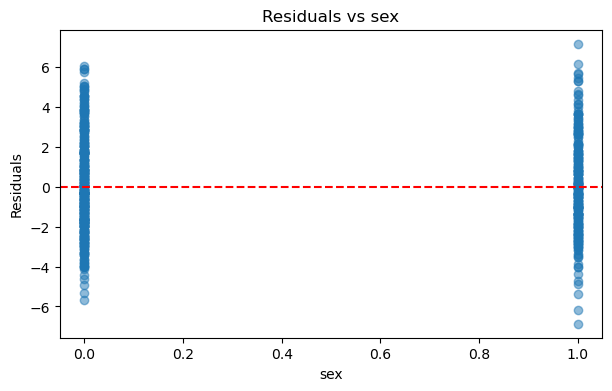

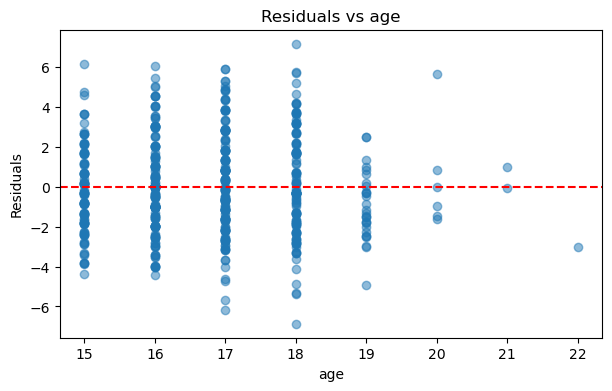

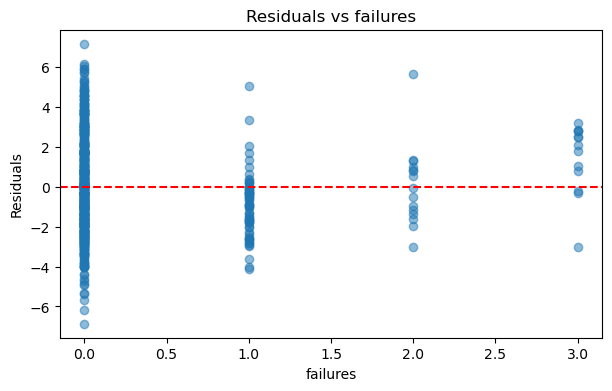

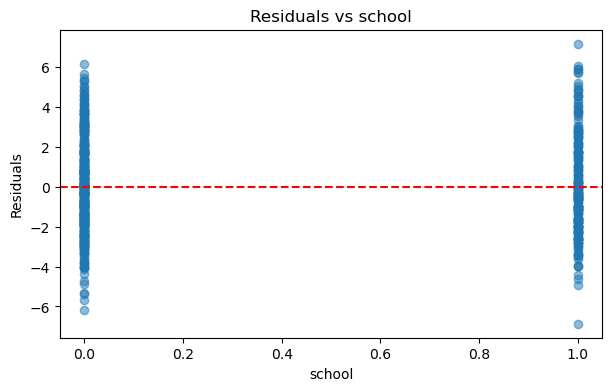

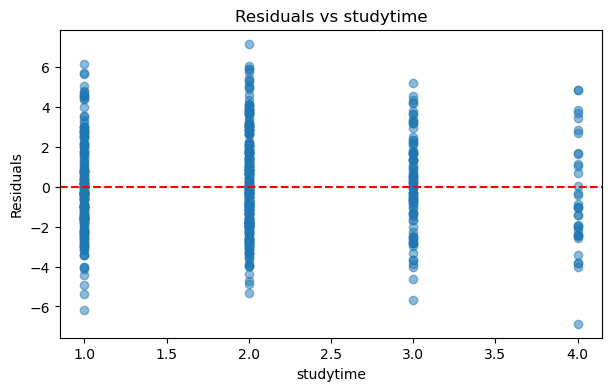

In [11]:
for col in X.columns:
    plt.figure(figsize=(7,4))
    plt.scatter(X[col], residuals, alpha=0.5)
    plt.axhline(0, color='red', linestyle='--')
    plt.xlabel(col)
    plt.ylabel('Residuals')
    plt.title(f'Residuals vs {col}')
    plt.show()

### Independence of errors

Durbin-Watson = (1.72) -> no autocorrelation

### Homoscedasticity

In [13]:
bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

labels = ['LM Statistic', 'LM p-value',
          'F Statistic', 'F p-value']

print(dict(zip(labels, bp_test)))

{'LM Statistic': np.float64(15.151997704094969), 'LM p-value': np.float64(0.0097322404610215), 'F Statistic': np.float64(3.075287943042532), 'F p-value': np.float64(0.009434573605158321)}


Data are still heteroscedastic.

Even with the robust regression, both coefficients are still significant

In [14]:
model_robust = model.get_robustcov_results(
    cov_type='HC3'
)

print(model_robust.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.228
Model:                            OLS   Adj. R-squared:                  0.222
Method:                 Least Squares   F-statistic:                     42.81
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           5.60e-38
Time:                        10:17:56   Log-Likelihood:                -1434.4
No. Observations:                 633   AIC:                             2881.
Df Residuals:                     627   BIC:                             2907.
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.3636      1.329      7.048      0.0

### Normality of residuals

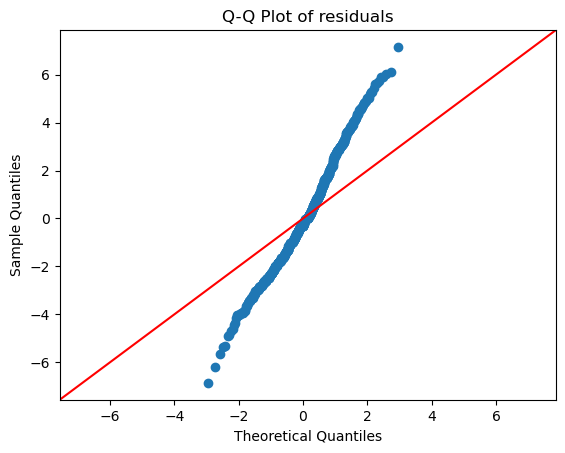

In [15]:
sm.qqplot(residuals, line='45')
plt.title('Q-Q Plot of residuals')
plt.show()

Shapiro-Wilk test
* $H_0$ : Residuals follow a normal distribution
* $H_1$ : Residuals DO NOT follow a normal distribution

In [17]:
stat, p_value = shapiro(model.resid)

print("Statistic:", stat)
print("P-value:", p_value)

Statistic: 0.9885644589094194
P-value: 7.528543520865432e-05


Again, the assumption of normality of residuals is violated

* Estimate of coefficients and errors are separate concepts
* alongside the normality of residuals, the distribution of estimated of coefficients with a large sample (N = 633) is also important
* with the central limit theorem, the distribution of coefficients can be approximated as normal even if individual errors are not normally distributed, because the estimate of coefficients becomes more accurate with large datasets 

## Candidate outliers

In [18]:
infl = model.get_influence()

df['standardized_residuals'] = (
    infl.resid_studentized_internal
)

outlier = df[
    np.abs(df['standardized_residuals']) > 3
]

print(outlier)

     sex  age  failures  school  studytime  G3  standardized_residuals
636    1   18         0       1          2  19                3.071496


## Influence

In [19]:
influence = model.get_influence()

cooks_distance = influence.cooks_distance[0]

df['cooks_distance'] = cooks_distance

print(
    df.sort_values(
        'cooks_distance',
        ascending=False
    ).head(10)
)

     sex  age  failures  school  studytime  G3  standardized_residuals  \
523    1   18         0       1          4   6               -2.965249   
351    1   20         2       0          1  15                2.435506   
279    1   22         3       0          1   5               -1.333612   
636    1   18         0       1          2  19                3.071496   
170    0   18         3       0          1  11                1.387012   
557    0   17         3       1          2  10                1.248170   
606    0   17         0       1          4  18                2.090102   
595    1   18         0       1          1  17                2.434358   
169    1   17         3       0          1  10                1.211694   
78     1   17         3       0          1  10                1.211694   

     cooks_distance  
523        0.036378  
351        0.027004  
279        0.018132  
636        0.017412  
170        0.015074  
557        0.012381  
606        0.011921  
595      

In [20]:
cooks_threshold = 4 / len(df)
print(cooks_threshold)

0.00631911532385466


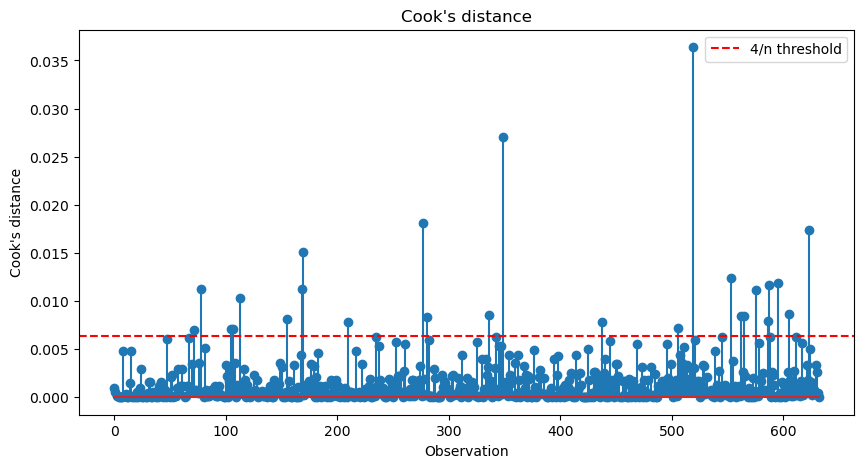

In [21]:
plt.figure(figsize=(10, 5))

plt.stem(
    np.arange(len(df)),
    df['cooks_distance']
)

plt.axhline(
    cooks_threshold,
    color='red',
    linestyle='--',
    label='4/n threshold'
)

plt.xlabel('Observation')
plt.ylabel("Cook's distance")
plt.title("Cook's distance")
plt.legend()
plt.show()

# Conclusions

> Heteroscedasticity of residuals

Heteroscedasticity means that the variance of errors is not constant with respect to the values of the independent variable or predicted values.\
It `does not distort estimates of coefficients` of OLS regression.\
Heteroscedasticity-Consistent Standard Errors were calculated with the correction HC3 (best in small/medium samples, when there are observations with high leverage).\
For calculations on p-values and confidence intervals, the HC3 correction is more reliable.

> Non-normality of residuals

It `does not distort estimates of coefficients` of OLS regression.\
Even if the Shapiro-Wilk test Rejected the Hypothesis of a normal distribution, the Q-Q plot shows that the majority of observations follow the expected trend, with some exceptions at the tails, suggesting that deviations from normality are not marked for the majority of observations.\
Considering the number of observations (N = 633), asymptotic properties of OLS estimators and the `central limit theorem` can be employed to approximate the distribution of estimators to a normal distribution, even if the distribution of residuals is not normal.

> Model

The `model cannot predict if a student will quit`.\
The model predicts the effects on final grade by:
* sex = *males have a lower score (almost 0.5 points)*
* age = *older students have higher scores (almost 0.2 points per year)*
* failures = *students who failed previously will have lower scores (more than 1.5 points)*
* school = *students of MS, i.e. Mousinho da Silveira will have lower scores (almost 1.0 points)*
* studytime = *student with higher studytime will perform better (almost 0.5 points per category increase)*

## RMSE and MAE

They will be calculated:
* in-sample = *on the sample used to estimate the regression*
    * evaluates how well the model describes the data
    * measuring the adaptament error
* out-of-sample = *on a test sub-set*
    * evaluates how well the model can generalize on new data
    * measuring the predictive capability

In [24]:
y_pred = model.predict(X)

mae_in = mean_absolute_error(y, y_pred)
rmse_in = np.sqrt(mean_squared_error(y, y_pred))

print("MAE in-sample:", round(mae_in, 3))
print("RMSE in-sample:", round(rmse_in, 3))

MAE in-sample: 1.87
RMSE in-sample: 2.333


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

model_train = sm.OLS(y_train, X_train).fit()

y_pred_test = model_train.predict(X_test)

mae_out = mean_absolute_error(y_test, y_pred_test)
rmse_out = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("MAE out-of-sample:", round(mae_out, 3))
print("RMSE out-of-sample:", round(rmse_out, 3))

MAE out-of-sample: 1.951
RMSE out-of-sample: 2.389


In [26]:
results = pd.DataFrame({
    'MAE': [mae_in, mae_out],
    'RMSE': [rmse_in, rmse_out]
}, index=['In-sample', 'Out-of-sample'])

display(round(results, 3))

,MAE,RMSE
In-sample,1.870,2.333
Out-of-sample,1.951,2.389


* In-sample and out-of-sample values are similar = the model has stable predictive capability
* When RMSE is a lot higher than MAE, there could be some high prediction errors

For the ratio between in-sample and out-of-sample.

$\delta$% = $\frac{OOS - IS}{IS} * 100$

where OOS = Out-of-sample, IS = In-sample

| $\delta$%        | Indicative interpretation       |
|------------------|---------------------------------|
| 0 - 5            | Optimal stability               |
| 5 - 10           | Good stability                  |
| 10 - 20          | Possible overfitting            |
| 20 - 30          | Likely overfitting              |
| > 30             | Significant overfitting         |

| Ratio RMSE / MAE | Indicative interpretation       |
|------------------|---------------------------------|
| 1.00 - 1.10      | Homogeneous errors              |
| 1.10 - 1.25      | Possible large errors           |
| 1.25 - 1.50      | Some large errors               |
| 1.50 - 2.00      | Very large errors               |
| > 2              | Large influence of large errors |

In [37]:
print("delta MAE:",
      round((mae_out - mae_in) / mae_in * 100, 2)
)
print("delta RMSE:",
      round((rmse_out - rmse_in) / rmse_in * 100, 2)
)

print("Ratio RMSE/MAE in-sample:",
      round(rmse_in / mae_in, 2)
)

print("Ratio RMSE/MAE out-of-sample:",
      round(rmse_out / mae_out, 2)
)

delta MAE: 4.33
delta RMSE: 2.39
Ratio RMSE/MAE in-sample: 1.25
Ratio RMSE/MAE out-of-sample: 1.22


Optimal stability but possible large errors

To check large errors

MAE: 1.9505663638764974
90° percentile: 3.9845171794910565
95° percentile: 4.688102107605649
Max error: 6.235163373381559


<Axes: ylabel='Count'>

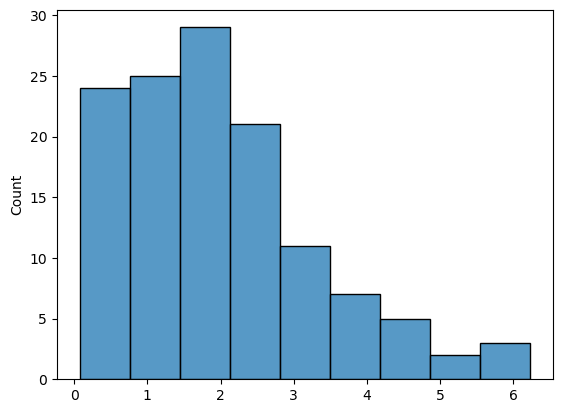

In [27]:
errors = np.abs(y_test - y_pred_test)

print("MAE:", errors.mean())
print("90° percentile:", np.percentile(errors, 90))
print("95° percentile:", np.percentile(errors, 95))
print("Max error:", errors.max())
sns.histplot(errors)